In [1]:
import os

import numpy as np
import scipy as sc
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
from scipy.stats import gaussian_kde
from scipy.spatial.distance import jensenshannon

In [4]:
import libraries.metrics as ms

In [6]:
file_path = r"datas\RT_labels.csv"
RT_labels = pd.read_csv(file_path, index_col = 0, sep = ";", encoding="utf-8")
RT_labels

,number,area,length,thickness,slant,width,height,mu_x,mu_y,sigma_x,sigma_y
0,5,107.3125,50.266504,2.460658,0.231074,14.539572,19.849054,8,10,6.517720,6.090501
1,0,123.2500,51.198485,2.616601,0.331858,15.387810,19.341053,15,21,5.409888,5.266861
2,4,78.3750,45.927670,1.891592,-0.212196,20.479656,19.114880,11,21,4.930632,4.015509
3,1,67.3125,22.849242,2.919769,0.509185,5.358179,19.724599,7,20,5.257078,4.658485
4,9,91.1875,46.284271,2.247425,0.007590,13.275437,19.527523,15,11,5.623913,3.899797
...,...,...,...,...,...,...,...,...,...,...,...
59995,8,102.1875,61.415999,1.941380,0.366472,11.840672,19.937599,16,14,5.473124,4.626496
59996,3,108.5625,46.705844,2.538071,0.364359,13.325950,19.688557,6,12,4.361458,5.032880
59997,5,87.0625,44.523864,2.058077,0.257784,14.133500,20.070647,24,14,3.967261,7.311521
59998,6,82.2500,53.337572,1.667193,0.310377,15.251961,19.692976,14,16,5.369598,4.904378


In [12]:
RT_labels.columns

Index(['number', 'area', 'length', 'thickness', 'slant', 'width', 'height',
       'mu_x', 'mu_y', 'sigma_x', 'sigma_y'],
      dtype='str')

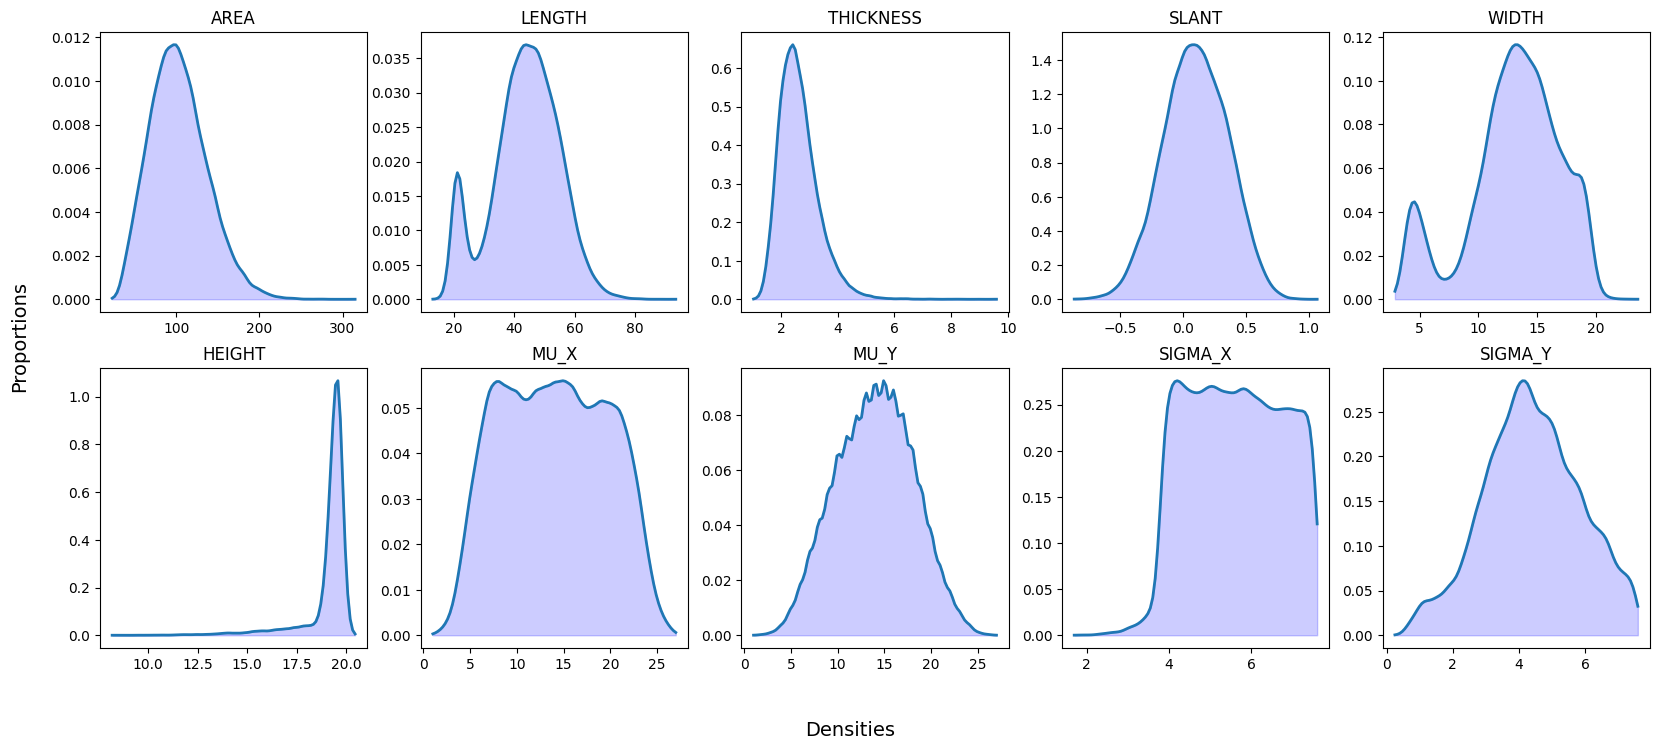

In [29]:
path = r"IMG"

w, h = 5, 2
s = 4
fig = plt.figure(figsize = (s*w, s*h))

for i, col in enumerate(list(RT_labels.columns[1:11])) : # +list(RT_labels.columns[-2:])
    Y = RT_labels[col]
    kde_y = gaussian_kde(Y)
    
    grid = np.linspace(Y.min(), Y.max(), 100) 
    p_Y = kde_y(grid)

    plt.subplot(h,w, i+1)
    plt.title(col.upper())
    plt.plot(grid, p_Y, linewidth = 2)
    plt.fill_between(
        x= grid, 
        y1= p_Y, 
        color= "b",
        alpha= 0.2)

    # plt.ylim(0, 1.0)
    # plt.grid(axis = "y")

fig.text(0.5, 0.0, 'Densities', ha='center', fontsize = 14)
fig.text(0.08, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)
fig.savefig(os.path.join(path, "RT-Morpho-MNIST - Density.pdf"), bbox_inches = 'tight')

In [31]:
path_X_real = '../R/RB/DATAS/MNIST/F32 - L043.csv'
path_Y_real = r"datas\RT_labels_trunc - 10_7_7_5_5_5_5_5_5_5_5.csv"
path_X_real, path_Y_real

('../R/RB/DATAS/MNIST/F32 - L043.csv',
 '../R/RB/DATAS/Morpho-MNIST/original-trunc/train-morpho-trunc - 7_7_7_6_5_10.csv')

In [32]:
path_X_gen = r"..\POC\MNIST_GENERATED\Morpho-MNIST - 7_7_7_6_5_10 - 60k.csv"

In [33]:
X_real = pd.read_csv(path_X_real, sep = ";")
Y_real = pd.read_csv(path_Y_real, sep = ",", index_col=0)
Y_real = Y_real.reset_index(drop = True)

In [34]:
X_gen = pd.read_csv(path_X_gen, index_col=0)
X_gen = X_gen.reset_index(drop = True)
Y_gen = X_gen.iloc[:, 20:]
X_gen = X_gen.iloc[:, :20]
X_gen

,33,30,6,7,22,1,40,28,16,38,12,39,17,23,25,29,35,15,32,0
0,2.004924,-0.590557,0.415072,-0.167904,-0.335996,-0.279202,-0.690392,-1.655021,-0.151466,-0.647361,0.399771,1.494287,-0.163161,1.978024,1.489863,-0.472832,1.884759,0.462151,0.831067,0.827141
1,0.382285,2.000831,0.658125,0.059961,0.269024,1.829787,-0.117468,1.678305,-0.083987,1.468408,-0.733069,1.865662,0.772475,-0.030177,-0.154269,-0.628052,0.630842,1.062634,-0.836210,1.008409
2,-1.248575,-0.340781,-1.040502,0.383173,-0.020790,0.382868,0.401414,-1.464536,0.840647,-0.687387,1.502110,-0.164412,0.558293,0.012166,0.493480,-2.640077,-1.109583,-1.991710,-1.168452,0.031674
3,-1.170156,0.022601,0.448766,0.265181,0.021670,1.849193,1.882171,-0.546913,-0.874713,-0.438097,0.255691,0.824926,1.613336,0.318368,-0.931482,-0.038147,1.080221,-0.317552,0.821796,1.548859
4,0.475829,-1.943162,0.659576,0.082466,-0.956054,0.161125,0.270648,-0.307947,0.219721,0.985416,-0.704141,-0.630983,-0.543242,0.795940,0.049532,-1.323198,-1.569919,-0.309761,-3.094620,0.180772
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,-0.716168,-0.072589,-1.302590,0.328570,-1.041675,1.648728,-0.726230,-0.298770,0.205071,0.133761,-1.328888,0.720451,0.897112,-0.731058,-2.266037,-0.598181,-0.323255,0.128899,-1.804766,0.389866
59996,0.352908,0.789036,-1.882342,0.762108,0.194820,0.930688,0.755957,0.510383,0.621930,1.342056,-2.196979,0.316430,0.368882,1.842354,2.034240,-0.173992,1.186875,0.884793,-0.139963,-0.239770
59997,0.724087,0.055039,-0.134500,-1.391045,0.633168,-0.976137,0.491491,0.623727,-1.570422,0.215398,-0.345557,-0.788590,0.318429,0.069008,-0.552269,-0.439116,-0.112040,-0.870962,-0.276148,1.305627
59998,1.163966,0.685815,0.402129,1.240405,-0.465392,0.318623,1.420777,-0.273178,0.739815,0.250248,-1.341513,-0.628647,0.364506,-1.053092,0.876892,0.754974,0.933323,0.528130,-1.020088,-1.102475


In [35]:
def D_KL(P, Q) : 
    return (P*np.log(P/Q)).sum()

def Jensen_Shannon(P, Q) :
    M = (P+Q)/2
    return (D_KL(P, M) +D_KL(Q, M)) /2 


JS_per_col = []
for col in Y_real.columns :
    P = Y_real[col].value_counts().sort_index() /len(Y_real)
    Q = Y_gen[col].value_counts().sort_index() /len(Y_gen)
    JS_per_col.append(Jensen_Shannon(P, Q))
    print(col, " : ", JS_per_col[-1])

JS_per_col

area  :  1.1349144746753445e-05
thickness  :  2.4046763520236517e-05
slant  :  4.403940251935872e-06
width  :  1.6713341648512446e-05
height  :  3.580570824376282e-06
number  :  2.4309490998200133e-05


[1.1349144746753445e-05,
 2.4046763520236517e-05,
 4.403940251935872e-06,
 1.6713341648512446e-05,
 3.580570824376282e-06,
 2.4309490998200133e-05]

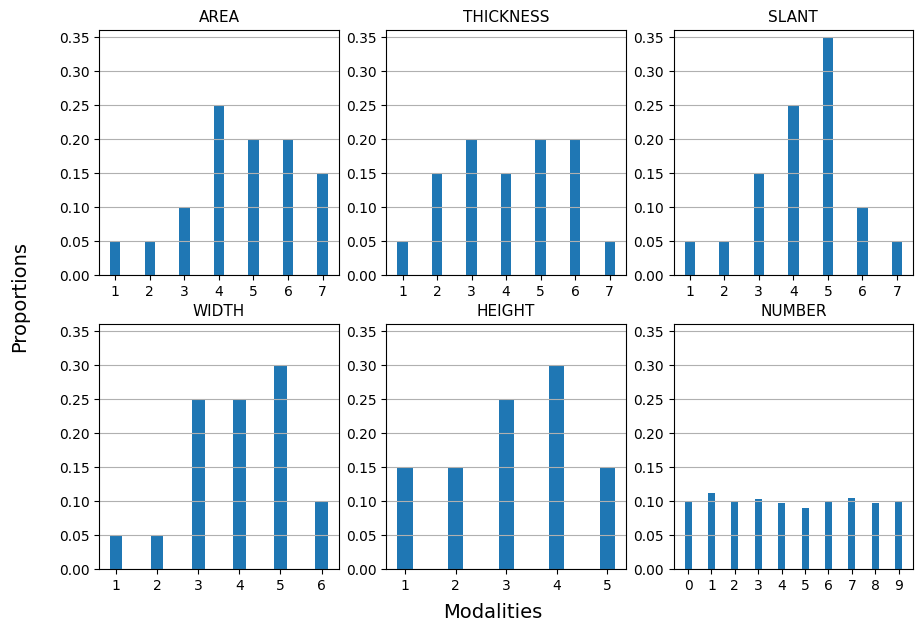

In [12]:
w, h = 3, 2

fig = plt.figure(figsize = (3.5*w, 3.5*h))

for i, col in enumerate(Y_real.columns) :
    plt.subplot(h, w, i +1)
    nb_mod = Y_real[col].unique()
    eff = len(Y_real)

    curr_Y_real = Y_real[[col]].value_counts().reset_index()
    curr_Y_gen = Y_gen[[col]].value_counts().reset_index()
    
    width = 0.15
    plt.bar(curr_Y_real[col], curr_Y_real[0] /60000, width = 2*width)

    plt.title(f'{col.upper()}', fontsize = 11)
    plt.ylim(0, 0.36)
    plt.grid(axis = "y")
    
    modality = sorted(curr_Y_real[col].unique())
    plt.xticks(modality)
        
fig.text(0.5, 0.04, 'Modalities', ha='center', fontsize = 14)
fig.text(0.04, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)

fig.savefig(os.path.join(path, "Y_disc - Global dicrete distrib.pdf"))

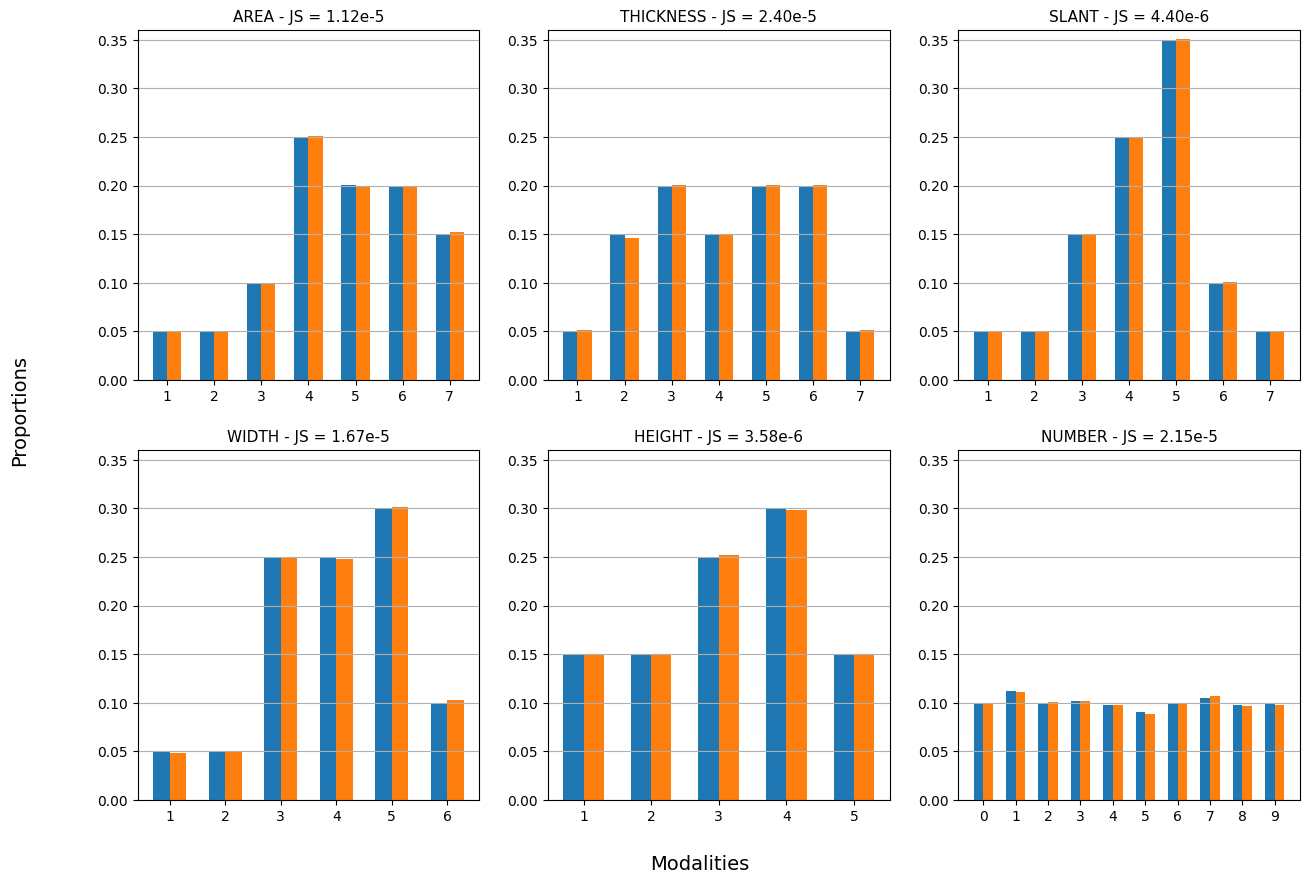

In [18]:

w, h = 3, 2
fig = plt.figure(figsize = (5*w, 5*h))

for i, col in enumerate(Y_real.columns) :
    plt.subplot(h, w, i +1)
    nb_mod = Y_real[col].unique()
    eff = len(Y_real)

    curr_Y_real = Y_real[[col]].value_counts().reset_index()
    curr_Y_gen = Y_gen[[col]].value_counts().reset_index()
    curr_Y_real.columns = [curr_Y_real.columns[0], "count"]
    curr_Y_gen.columns = [curr_Y_gen.columns[0], "count"]
    JS = ms.Jensen_Shannon(curr_Y_real["count"]/eff, curr_Y_gen["count"]/eff)

    width = 0.15
    plt.bar(curr_Y_real[col] -width, curr_Y_real["count"]/eff, width = 2*width)
    plt.bar(curr_Y_gen[col] +width, curr_Y_gen["count"]/eff, width = 2*width)

    plt.title(f'{col.upper()} - JS = {ms.format_pow10(JS)}', fontsize = 11)
    plt.ylim(0, 0.36)
    plt.grid(axis = "y")
    
    modality = sorted(curr_Y_gen[col].unique())
    
    
    plt.xticks(modality)

fig.text(0.5, 0.04, 'Modalities', ha='center', fontsize = 14)
fig.text(0.04, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)

fig.savefig(os.path.join(path, "Global dicrete distrib.png"))

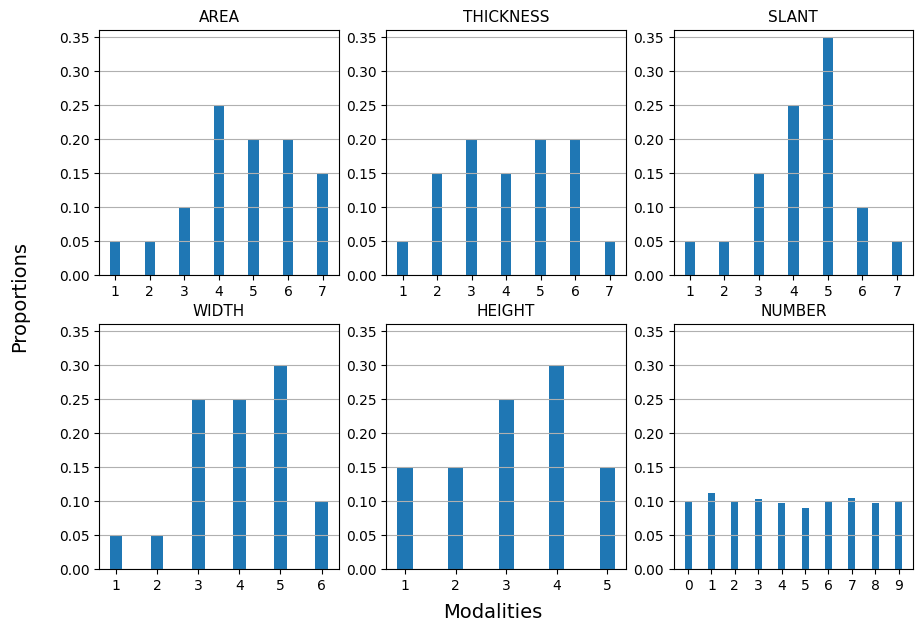

In [19]:
w, h = 3, 2

fig = plt.figure(figsize = (3.5*w, 3.5*h))

for i, col in enumerate(Y_real.columns) :
    plt.subplot(h, w, i +1)
    nb_mod = Y_real[col].unique()
    eff = len(Y_real)

    curr_Y_real = Y_real[[col]].value_counts().reset_index()
    curr_Y_gen = Y_gen[[col]].value_counts().reset_index()
    curr_Y_real.columns = [curr_Y_real.columns[0], "count"]
    curr_Y_gen.columns = [curr_Y_gen.columns[0], "count"]
    
    width = 0.15
    plt.bar(curr_Y_real[col], curr_Y_real["count"] /eff, width = 2*width)

    plt.title(f'{col.upper()}', fontsize = 11)
    plt.ylim(0, 0.36)
    plt.grid(axis = "y")
    
    modality = sorted(curr_Y_real[col].unique())
    plt.xticks(modality)
        
fig.text(0.5, 0.04, 'Modalities', ha='center', fontsize = 14)
fig.text(0.04, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)

fig.savefig(os.path.join(path, "Y_disc - Global dicrete distrib"))

In [15]:
curr_Y_real.columns

Index(['number', 'count'], dtype='object')

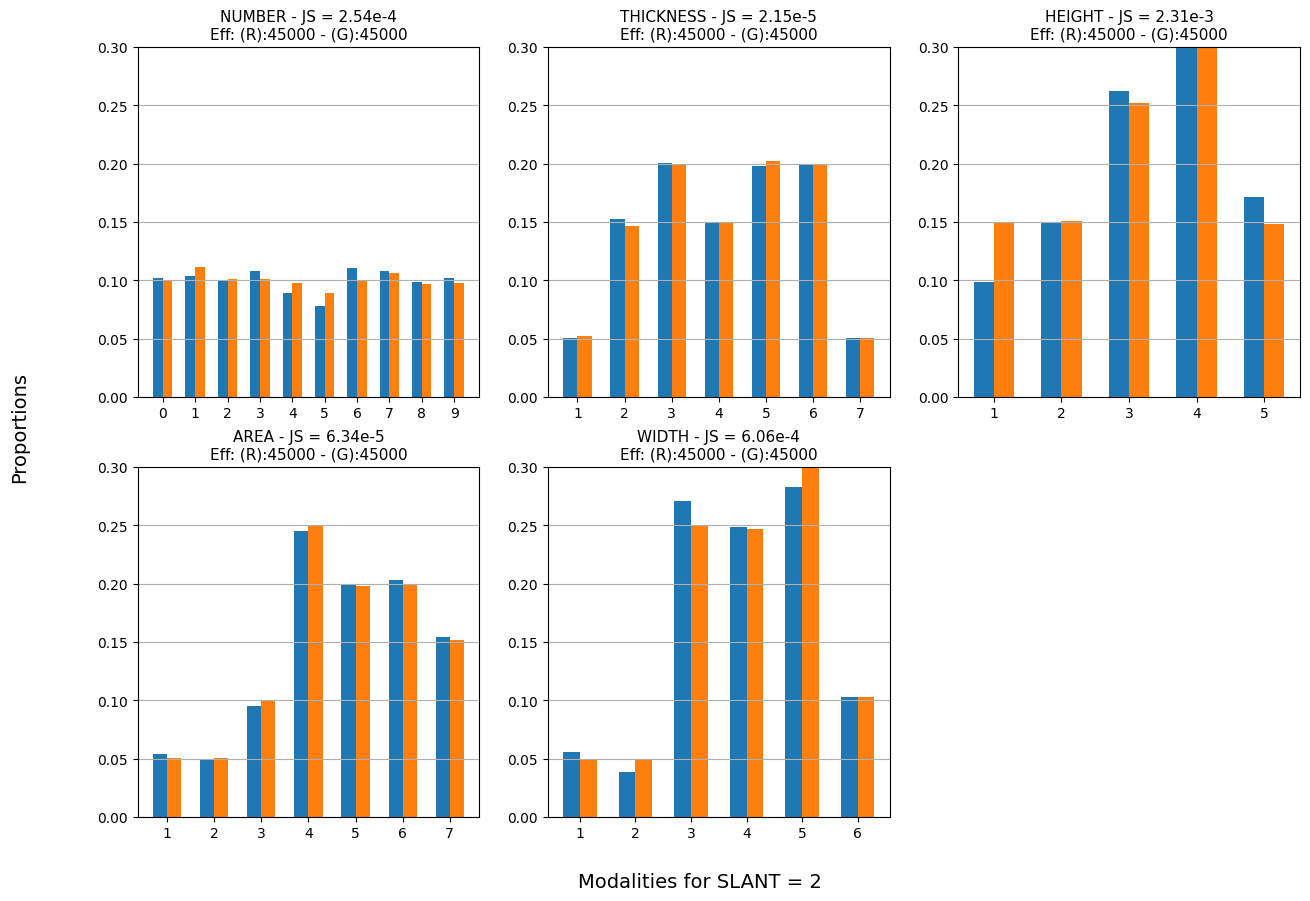

In [22]:
curr_col = "slant"
mod_curr_col = sorted(Y_real[curr_col].unique())
m = 2
curr_Y_real = Y_real[(Y_real[curr_col] >= 3) & (Y_real[curr_col] <= 5)]
curr_Y_gen = Y_gen.loc[curr_Y_real.index, :]



w, h = 3, 2
fig = plt.figure(figsize = (5*w, 5*h))

cols = list(set(curr_Y_real.columns) - set([curr_col]))
for i, col in enumerate(cols) :
    plt.subplot(h, w, i +1)
    nb_mod = curr_Y_real[col].unique()
    eff_real = len(curr_Y_real)
    eff_gen = len(curr_Y_gen)

    curr_y_real = curr_Y_real[[col]].value_counts().reset_index()
    curr_y_gen = curr_Y_gen[[col]].value_counts().reset_index()
    curr_y_real.columns = [curr_y_real.columns[0], "count"]
    curr_y_gen.columns = [curr_y_gen.columns[0], "count"]
    JS = ms.Jensen_Shannon(curr_y_real["count"]/eff, curr_y_gen["count"]/eff)

    width = 0.15
    plt.bar(curr_y_real[col] -width, curr_y_real["count"]/eff_real, width = 2*width)
    plt.bar(curr_y_gen[col] +width, curr_y_gen["count"]/eff_gen, width = 2*width)

    plt.title(f'{col.upper()} - JS = {ms.format_pow10(JS)}\nEff: (R):{eff_real} - (G):{eff_gen}', fontsize = 11)
    plt.ylim(0, 0.3)
    plt.grid(axis = "y")
    
    modality = sorted(curr_y_gen[col].unique())
    plt.xticks(modality)

fig.text(0.5, 0.04, f'Modalities for {curr_col.upper()} = {m}', ha='center', fontsize = 14)
fig.text(0.04, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)

fig.savefig(f"../IMG/Dicrete distrib - {curr_col.upper()} = {m}.png")

In [ ]:
curr_col = "thickness"
curr_col_2 = "width"
mod_curr_col = sorted(Y_real[curr_col].unique())
m = 4
m2 = 4
curr_Y_real = Y_real[(Y_real[curr_col] >= m)&(Y_real[curr_col_2] >= m2)]
curr_Y_gen = Y_gen[(Y_gen[curr_col] >= m)&(Y_gen[curr_col_2] >= m2)]

In [ ]:
curr_col = "area"
curr_col_2 = "number"
mod_curr_col = sorted(Y_real[curr_col].unique())
m = 5
m2 = 1
curr_Y_real = Y_real[(Y_real[curr_col] >= m)&(Y_real[curr_col_2] == m2)]
curr_Y_gen = Y_gen[(Y_gen[curr_col] >= m)&(Y_gen[curr_col_2] == m2)]

In [71]:
curr_col = "area"
curr_col_2 = "number"
mod_curr_col = sorted(Y_real[curr_col].unique())
m = 3
m2 = 3
curr_Y_real = Y_real[(Y_real[curr_col] == m)&(Y_real[curr_col_2] == m2)]
curr_Y_gen = Y_gen[(Y_gen[curr_col] == m)&(Y_gen[curr_col_2] == m2)]

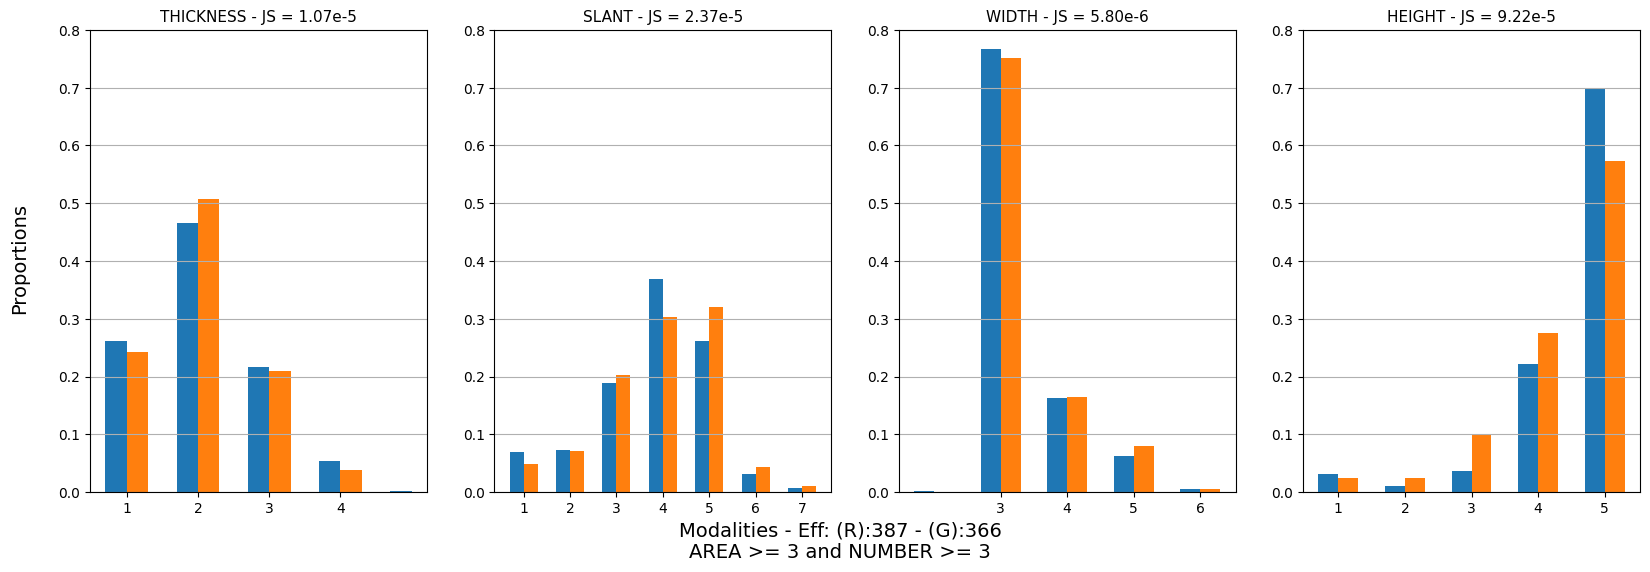

In [71]:
curr_col = "area"
curr_col_2 = "number"
mod_curr_col = sorted(Y_real[curr_col].unique())
m = 3
m2 = 3
curr_Y_real = Y_real[(Y_real[curr_col] == m)&(Y_real[curr_col_2] == m2)]
curr_Y_gen = Y_gen[(Y_gen[curr_col] == m)&(Y_gen[curr_col_2] == m2)]

w, h = 4, 1
fig = plt.figure(figsize = (5*w, 6*h))

cols = list(set(curr_Y_real.columns) - set([curr_col, curr_col_2]))
eff_real = len(curr_Y_real)
eff_gen = len(curr_Y_gen)
for i, col in enumerate(cols) :
    plt.subplot(h, w, i +1)
    nb_mod = curr_Y_real[col].unique()

    curr_y_real = curr_Y_real[[col]].value_counts().reset_index()
    curr_y_gen = curr_Y_gen[[col]].value_counts().reset_index()
    curr_y_real.columns = [curr_y_real.columns[0], "count"]
    curr_y_gen.columns = [curr_y_gen.columns[0], "count"]
    JS = Jensen_Shannon(curr_y_real["count"]/eff, curr_y_gen["count"]/eff)

    width = 0.15
    plt.bar(curr_y_real[col] -width, curr_y_real["count"]/eff_real, width = 2*width)
    plt.bar(curr_y_gen[col] +width, curr_y_gen["count"]/eff_gen, width = 2*width)

    plt.title(f'{col.upper()} - JS = {ms.format_pow10(JS)}', fontsize = 11)
    plt.ylim(0, 0.8)
    plt.grid(axis = "y")
    
    modality = sorted(curr_y_gen[col].unique())
    plt.xticks(modality)

fig.text(0.5, 0.0, f'Modalities - Eff: (R):{eff_real} - (G):{eff_gen}\n{curr_col.upper()} >= {m} and {curr_col_2.upper()} >= {m2}', ha='center', fontsize = 14)
fig.text(0.085, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)

fig.savefig(f"../IMG/Dicrete distrib - {curr_col.upper()} = {m} and {curr_col_2.upper()} = {m2}.pdf")

In [36]:
Y_real[curr_col]

1        5
2        6
3        4
4        3
5        4
        ..
59996    5
59997    5
59998    4
59999    4
60000    4
Name: area, Length: 60000, dtype: int64

In [ ]:
curr_col = "thickness"
curr_col_2 = "width"
mod_curr_col = sorted(Y_real[curr_col].unique())
m = 4
m2 = 4
curr_X_real = X_real[(Y_real[curr_col] >= mod_curr_col[m])&(Y_real[curr_col_2] >= m2)]
curr_X_gen = X_gen[(Y_gen[curr_col] >= mod_curr_col[m])&(Y_gen[curr_col_2] >= m2)]

In [56]:
curr_X_real[[col]].value_counts().reset_index()

,33,count
0,-0.648011,2
1,0.147185,2
2,-3.202241,1
3,-3.200950,1
4,-3.156009,1
...,...,...
25159,-3.029720,1
25160,-3.017259,1
25161,-3.004765,1
25162,-2.981784,1


In [ ]:
curr_col = "area"
curr_col_2 = "number"
m = 5
m2 = 1
curr_X_real = X_real[(Y_real[curr_col] >= m)&(Y_real[curr_col_2] == m2)]
curr_X_gen = X_gen[(Y_gen[curr_col] >= m)&(Y_gen[curr_col_2] == m2)]

In [ ]:
curr_col = "thickness"
curr_col_2 = "width"
m = 4
m2 = 4
curr_X_real = X_real[(Y_real[curr_col] >= m)&(Y_real[curr_col_2] >= m2)]
curr_X_gen = X_gen[(Y_gen[curr_col] >= m)&(Y_gen[curr_col_2] >= m2)]

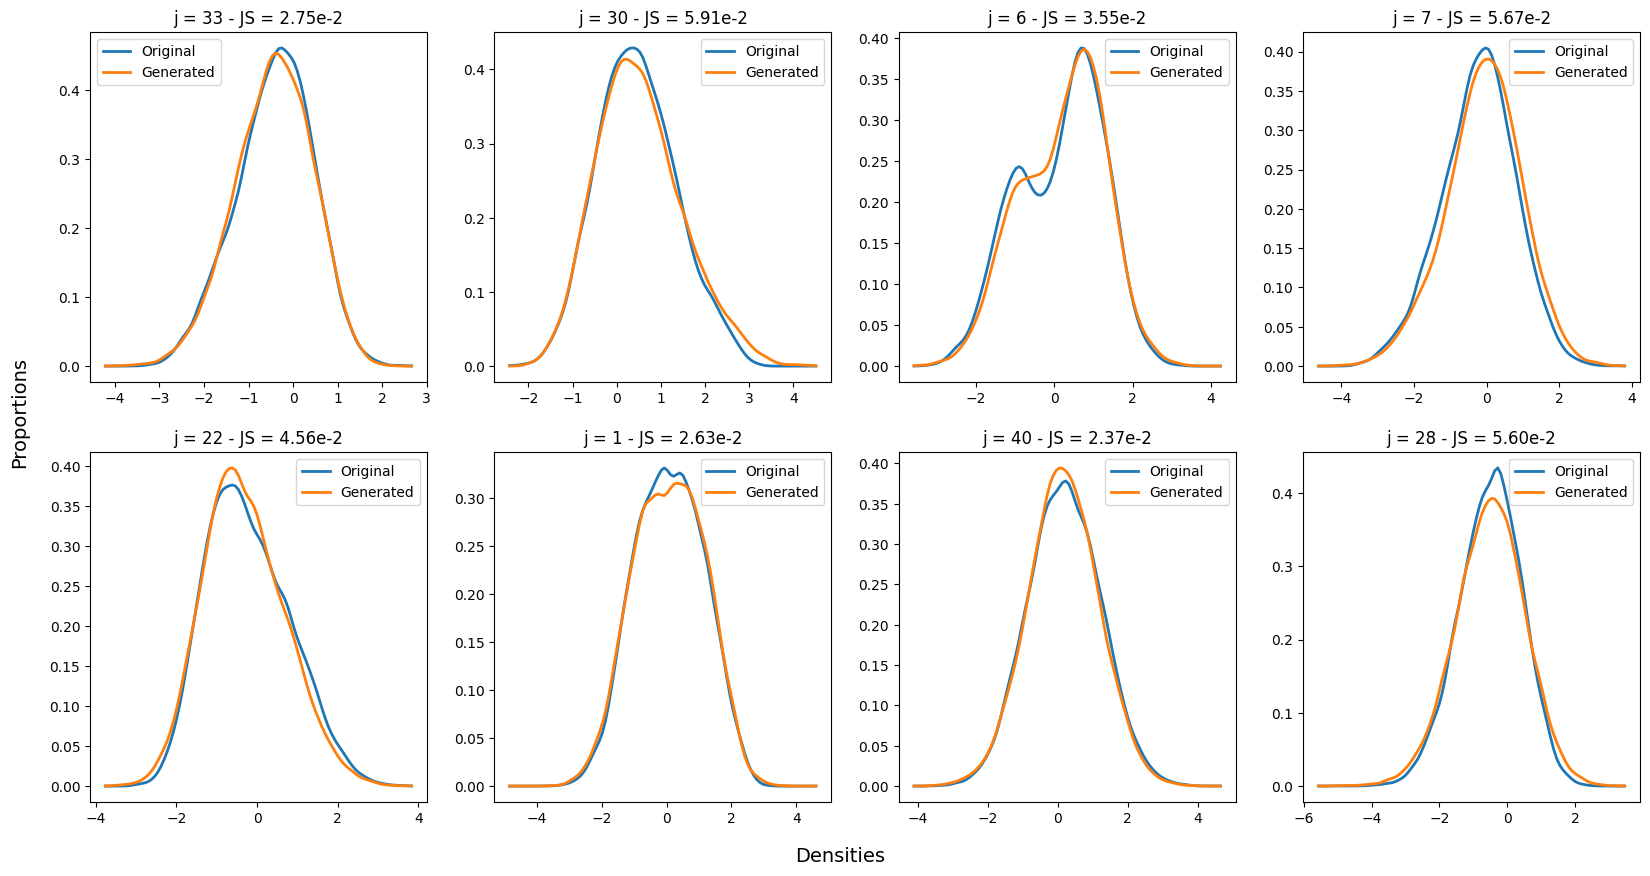

In [72]:
curr_col = "area"
curr_col_2 = "number"
mod_curr_col = sorted(Y_real[curr_col].unique())
m = 3
m2 = 3
curr_Y_real = Y_real[(Y_real[curr_col] == m)&(Y_real[curr_col_2] == m2)]
curr_Y_gen = Y_gen[(Y_gen[curr_col] == m)&(Y_gen[curr_col_2] == m2)]
w, h = 4, 2
fig = plt.figure(figsize = (5*w, 5*h))

for i, col in enumerate(X_real.columns[:8]) :

    curr_x_real = curr_X_real[col]
    curr_x_gen = curr_X_gen[col]
    
    plt.subplot(h, w, i +1)
    X, hat_X = curr_x_real, curr_x_gen
    kde_real = gaussian_kde(X)
    kde_gen = gaussian_kde(hat_X)
    xmin = min(X.min(), hat_X.min())
    xmax = max(X.max(), hat_X.max())
    
    grid = np.linspace(xmin, xmax, 100) # grids = [np.linspace(xmin, xmax, n) for n in [200, 500, 1000, 2000, 5000]]

    p_X = kde_real(grid)
    p_hat_X = kde_gen(grid)

    JS = np.round(jensenshannon(p_X, p_hat_X), 5)
    plt.plot(grid, p_X, linewidth = 2)
    plt.plot(grid, p_hat_X, linewidth = 2)
    plt.title(f'j = {col} - JS = {ms.format_pow10(JS)}')
    plt.legend(["Original", "Generated"])


fig.text(0.5, 0.05, f'Densities', ha='center', fontsize = 14)
fig.text(0.085, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)
fig.savefig(f"Countinuous distrib - {curr_col.upper()} = {m} and {curr_col_2.upper()} = {m2}.pdf")

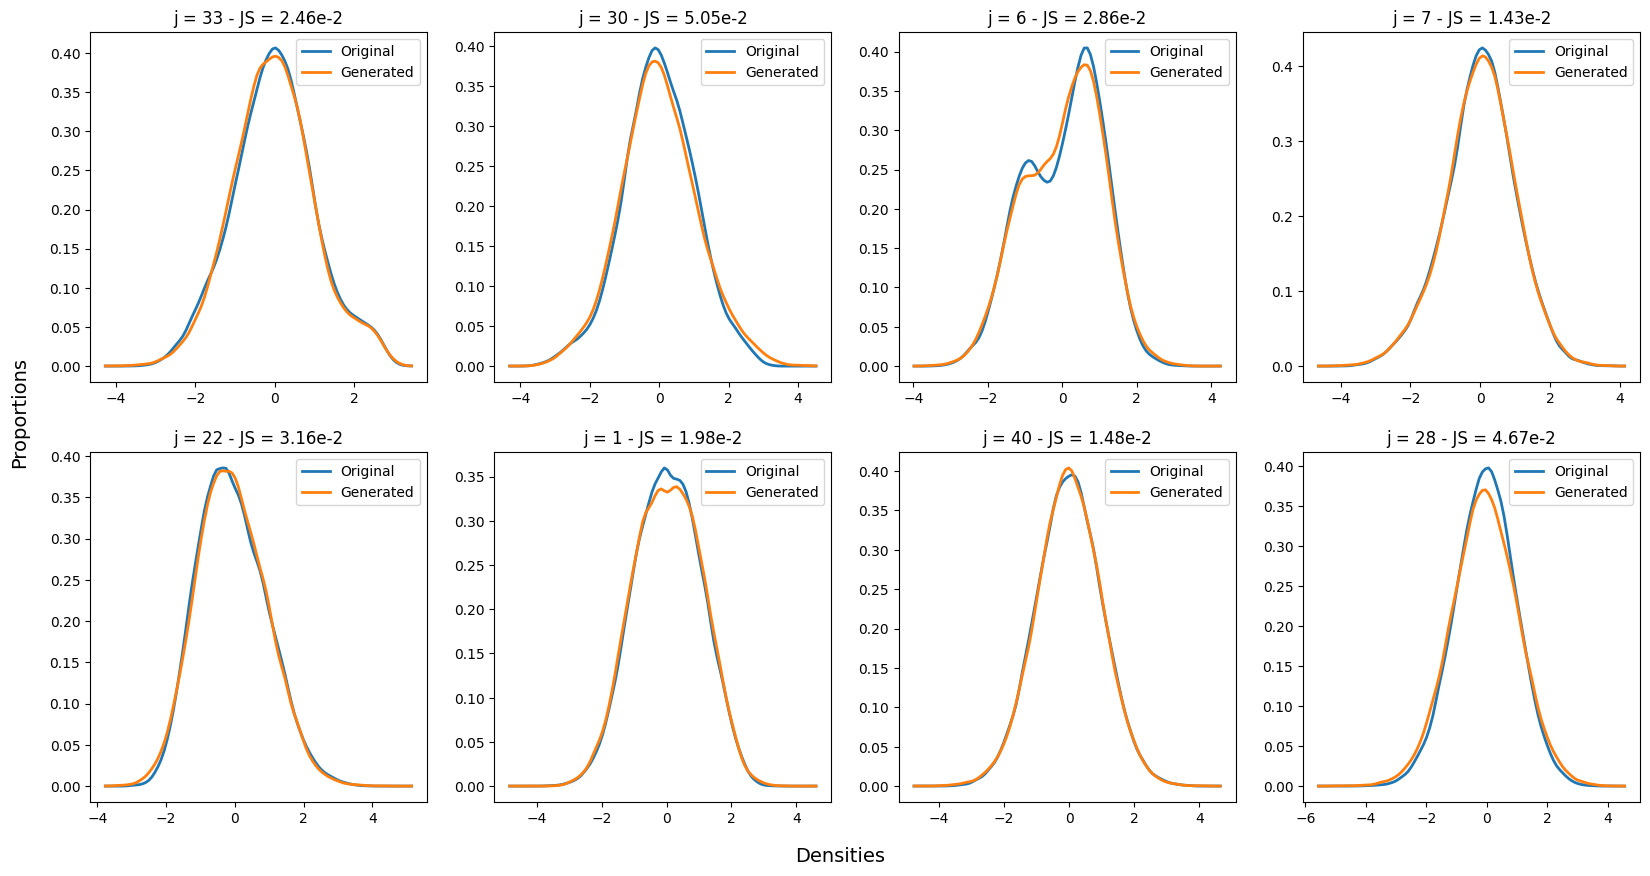

In [82]:
w, h = 4, 2
fig = plt.figure(figsize = (5*w, 5*h))

for i, col in enumerate(X_real.columns[:8]) :
    
    plt.subplot(h, w, i +1)
    X, hat_X = X_real[col], X_gen[col]
    kde_real = gaussian_kde(X)
    kde_gen = gaussian_kde(hat_X)
    xmin = min(X.min(), hat_X.min())
    xmax = max(X.max(), hat_X.max())
    
    grid = np.linspace(xmin, xmax, 100) # grids = [np.linspace(xmin, xmax, n) for n in [200, 500, 1000, 2000, 5000]]

    p_X = kde_real(grid)
    p_hat_X = kde_gen(grid)

    JS = np.round(jensenshannon(p_X, p_hat_X), 5)
    plt.plot(grid, p_X, linewidth = 2)
    plt.plot(grid, p_hat_X, linewidth = 2)
    plt.title(f'j = {col} - JS = {format_puissance_10(JS)}')
    plt.legend(["Original", "Generated"])


fig.text(0.5, 0.05, f'Densities', ha='center', fontsize = 14)
fig.text(0.085, 0.5, 'Proportions', va='center', rotation='vertical', fontsize = 14)
fig.savefig("Distrib countinuous.png")

(array([2.000e+00, 6.000e+00, 1.400e+01, 2.800e+01, 8.400e+01, 1.060e+02,
        2.870e+02, 4.950e+02, 8.320e+02, 1.311e+03, 1.931e+03, 2.711e+03,
        3.694e+03, 4.600e+03, 5.288e+03, 5.783e+03, 5.843e+03, 5.694e+03,
        5.287e+03, 4.597e+03, 3.616e+03, 2.659e+03, 2.029e+03, 1.323e+03,
        7.600e+02, 4.840e+02, 2.730e+02, 1.340e+02, 8.000e+01, 3.300e+01,
        7.000e+00, 4.000e+00, 1.000e+00, 2.000e+00, 1.000e+00, 1.000e+00]),
 array([-11., -10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,
          0.,   1.,   2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.,  10.,
         11.,  12.,  13.,  14.,  15.,  16.,  17.,  18.,  19.,  20.,  21.,
         22.,  23.,  24.,  25.]),
 <BarContainer object of 36 artists>)

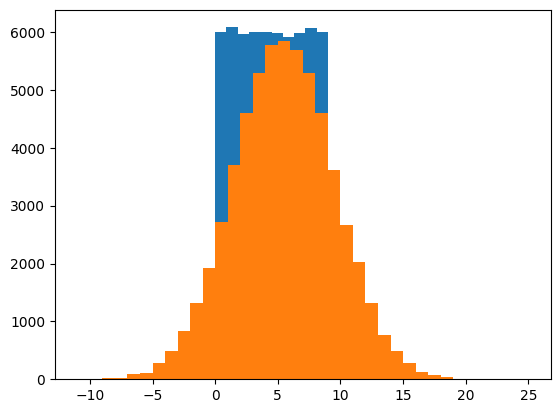

In [10]:
unif = pd.DataFrame(np.random.randint(0, 10, 60000), columns = ["val"])
normal = np.random.normal(5, 4, 60000)
normal = pd.DataFrame(np.array(np.round(normal, 0), dtype = int), columns = ["val"])

plt.hist(unif["val"], bins = 10)
plt.hist(normal["val"], bins=len(normal["val"].unique()))



In [11]:
unif = unif.value_counts().reset_index()
normal = normal.value_counts().reset_index()

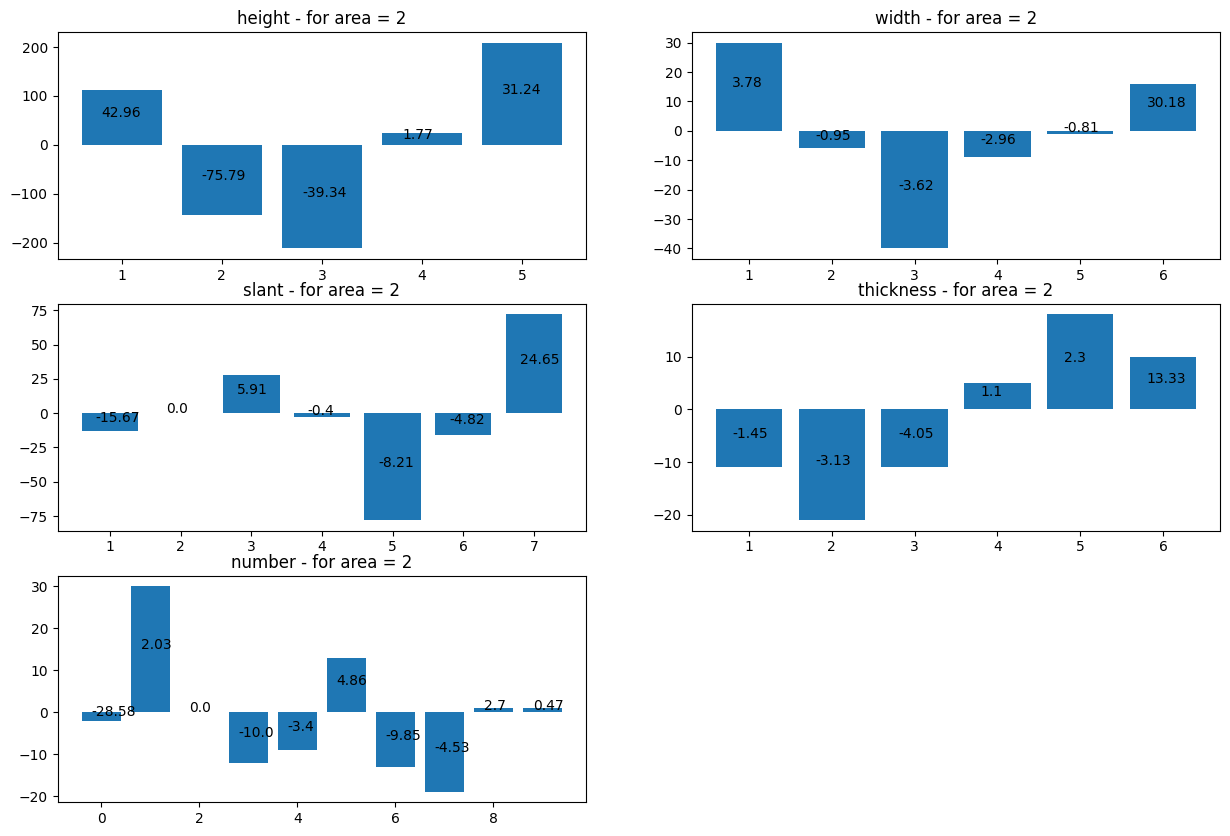

In [8]:
curr_col = "area"
mod_curr_col = sorted(Y_real[curr_col].unique())
m = 1
curr_Y_real = Y_real[Y_real[curr_col] == mod_curr_col[m]]
curr_Y_gen = Y_gen[Y_gen[curr_col] == mod_curr_col[m]]

w, h = 3, 2
plt.figure(figsize = (5*w, 5*h))

for i, col in enumerate(list(set(Y_real.columns) - set([curr_col]))) :

    plt.subplot(w, h, i +1)
    nb_mod = curr_Y_real[col].unique()

    col_curr_Y_real = curr_Y_real[[col]].value_counts().sort_index()
    col_curr_Y_gen = curr_Y_gen[[col]].value_counts().sort_index()

    col_curr_Y = (col_curr_Y_real -col_curr_Y_gen).reset_index()
    col_curr_Y["percent"] = col_curr_Y["count"]/col_curr_Y_real.reset_index()["count"] *10000 //1 /100
    plt.bar(x=col_curr_Y[col], height= col_curr_Y["count"])
    for mod in col_curr_Y[col].unique() :
        count = col_curr_Y[col_curr_Y[col] == mod]["count"]
        percent = col_curr_Y[col_curr_Y[col] == mod]["percent"]
        plt.text(mod -0.2, count.iloc[0]/2, f'{percent.iloc[0]}')
    plt.title(f'{col} - for {curr_col} = {mod_curr_col[m]}')